# 01 หลักการภาพ SAR และ Sentinel-1: polarization และภาพผสมสี

**ชุดการสอน:** Teach_SAR_flood_Mapping_ML | **เวลาโดยประมาณ:** 90 นาที | **ต้องทำก่อน:** `00`

## จุดประสงค์
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. อธิบายความต่างของ products หลักของ Sentinel-1 (SLC, GRD) และโหมด IW
2. อธิบายกลไก backscatter ที่ทำให้ผิวน้ำ นาข้าว และสิ่งปลูกสร้าง มีค่าต่างกัน
3. แปลงค่าระหว่าง dB กับ linear power และอ่าน histogram ของภาพ SAR
4. สร้างภาพผสมสีแบบ polarization และแบบสองช่วงเวลา เพื่อเน้นพื้นที่น้ำท่วม

## 0. เตรียมสภาพแวดล้อม
เซลล์นี้ดาวน์โหลดข้อมูลและฟังก์ชันกลาง (`sarflood_utils.py`) จาก GitHub ของรายวิชา **notebook นี้ไม่ต้องใช้ Google Earth Engine** เพราะข้อมูลถูกเตรียมไว้แล้วใน `00`

รูปทุกรูปใช้ป้ายกำกับภาษาอังกฤษ เพราะเป็นมาตรฐานของวารสารนานาชาติ และ Colab ไม่มีฟอนต์ไทยสำหรับ matplotlib

In [1]:
!pip -q install rasterio

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = 'Teach_SAR_flood_Mapping_ML'
if not os.path.isdir(REPO):
    !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git
sys.path.insert(0, REPO)
import sarflood_utils as su

DATA = f'{REPO}/data'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
print('ไฟล์ข้อมูล:', sorted(os.listdir(DATA)))

ไฟล์ข้อมูล: ['S1_20171017_VH.tif', 'S1_20171017_VV.tif', 'S1_20180109_VH.tif', 'S1_20180109_VV.tif', 'boundary_amphoe.geojson', 'boundary_province.geojson', 'dem_srtm.tif', 'ghsl_pop_2020.tif', 'jrc_seasonality.tif', 'readme.txt', 'slope_srtm.tif', 'worldcover_2020.tif']


## 1. หลักการโดยย่อ

**SAR (Synthetic Aperture Radar)** ส่งคลื่นไมโครเวฟลงมาเองแล้ววัดพลังงานที่สะท้อนกลับ จึงถ่ายได้ทั้งกลางวันกลางคืนและทะลุเมฆ เหมาะกับช่วงน้ำท่วมซึ่งมักมีเมฆปกคลุม Sentinel-1 ใช้ C-band ความยาวคลื่นประมาณ 5.6 ซม.

**Products ของ Sentinel-1**

| Product | เนื้อหา | ใช้ทำอะไร |
|---|---|---|
| SLC (Single Look Complex) | แอมพลิจูดและเฟส ยังอยู่ในเรขาคณิตของเรดาร์ | InSAR, การวิเคราะห์เฟส |
| **GRD (Ground Range Detected)** | เฉพาะแอมพลิจูด ผ่าน multi-look และฉายลงพื้นดินแล้ว | แผนที่น้ำท่วม สิ่งปกคลุมดิน (ใช้ในบทเรียนนี้) |
| OCN | ลมและคลื่นผิวทะเล | สมุทรศาสตร์ |

โหมด **IW (Interferometric Wide swath)** เป็นโหมดหลักบนแผ่นดิน แนวถ่ายภาพกว้าง 250 กม. ขนาดจุดภาพของ GRD คือ 10 ม.

**Polarization** ตัวอักษรแรกคือทิศที่ส่ง ตัวที่สองคือทิศที่รับ
- **VV** ส่งแนวตั้ง รับแนวตั้ง ไวต่อความขรุขระของผิวและความชื้นดิน
- **VH** ส่งแนวตั้ง รับแนวนอน เกิดจากการกระเจิงหลายทิศทางในเรือนยอดพืช (volume scattering)

**กลไก backscatter หลัก**

| พื้นผิว | กลไก | ผลบนภาพ |
|---|---|---|
| ผิวน้ำนิ่ง | สะท้อนแบบกระจกเงา (specular) ออกไปจากดาวเทียม | มืดมาก |
| ดินขรุขระ ทุ่งหญ้า | กระเจิงจากผิว (surface) | เทาปานกลาง |
| ป่า พืชสูง | กระเจิงในเรือนยอด (volume) | VH สว่าง |
| อาคาร ต้นไม้ที่มีน้ำท่วมโคน | สะท้อนสองครั้ง (double bounce) | VV สว่างมาก |

**หน่วยเดซิเบล** ค่า backscatter coefficient $\sigma^0$ มีช่วงกว้างมาก จึงนิยมแสดงเป็น dB

$$\sigma^0_{dB} = 10\,\log_{10}(\sigma^0) \qquad\Longleftrightarrow\qquad \sigma^0 = 10^{\,\sigma^0_{dB}/10}$$

ข้อควรจำ: การหาค่าเฉลี่ยหรือกรองภาพต้องทำบนค่า linear ส่วนการแสดงผลและการหาผลต่างนิยมทำบน dB

## 2. อ่านภาพทั้ง 4 แบนด์
ไฟล์เก็บค่า dB × 100 แบบจำนวนเต็ม ฟังก์ชัน `su.load_s1` หารด้วย 100 ให้แล้ว และกำหนดจุดภาพนอกพื้นที่ศึกษาเป็น `NaN`

In [2]:
dates = {'ref': su.REF_TAG, 'flood': su.FLOOD_TAG}
img = {}
for key, tag in dates.items():
    for pol in ['VV', 'VH']:
        img[key, pol], grid = su.load_s1(DATA, tag, pol)

amphoe, province = su.load_boundaries(DATA, grid['crs'])
print('ขนาดภาพ (แถว, คอลัมน์):', img['ref', 'VV'].shape, '| ขนาดจุดภาพ:', grid['transform'].a, 'ม.')

ขนาดภาพ (แถว, คอลัมน์): (5643, 4106) | ขนาดจุดภาพ: 10.0 ม.


In [3]:
# สถิติพื้นฐานของแต่ละแบนด์ (หน่วย dB)
rows = []
for (key, pol), a in img.items():
    v = a[np.isfinite(a)]
    rows.append({'date': dates[key], 'type': key, 'pol': pol, 'mean': v.mean(), 'std': v.std(),
                 'p5': np.percentile(v, 5), 'median': np.median(v), 'p95': np.percentile(v, 95)})
stats = pd.DataFrame(rows).round(2)
stats

,date,type,pol,mean,std,p5,median,p95
0,20180109,ref,VV,-6.26,5.64,-14.70,-7.53,0.0
1,20180109,ref,VH,-11.21,9.49,-24.08,-15.05,0.0
2,20171017,flood,VV,-7.54,7.72,-22.44,-7.03,0.0
3,20171017,flood,VH,-12.18,11.13,-30.70,-14.00,0.0


## 3. เปรียบเทียบ VV กับ VH ของสองวัน
ใช้ช่วงสีเดียวกันในแต่ละ polarization เพื่อให้เทียบความมืดสว่างข้ามวันได้

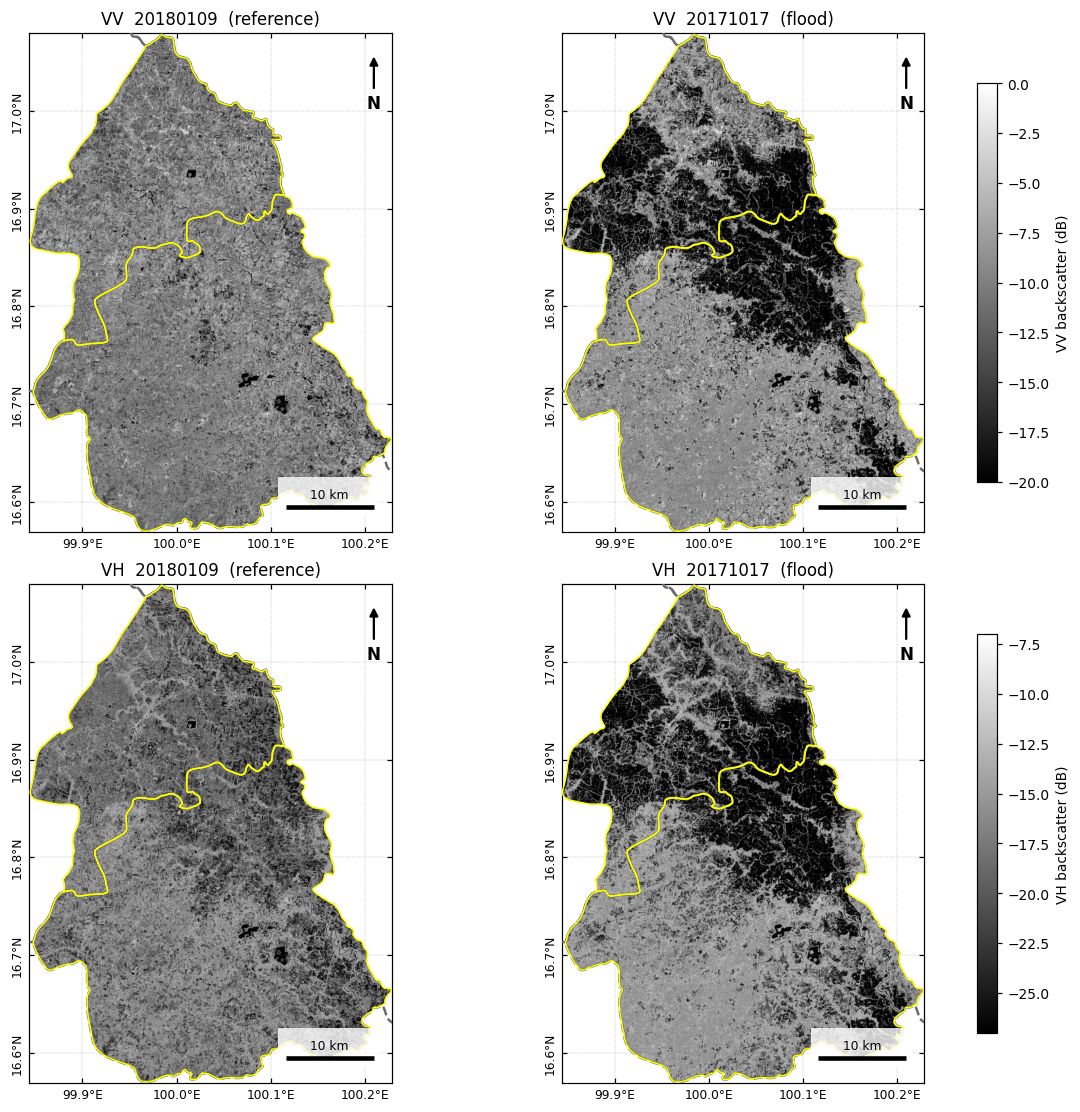

In [4]:
vlim = {'VV': (-20, 0), 'VH': (-27, -7)}
fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
for i, pol in enumerate(['VV', 'VH']):
    for j, key in enumerate(['ref', 'flood']):
        ax = axes[i, j]
        im = ax.imshow(img[key, pol], cmap='gray', vmin=vlim[pol][0], vmax=vlim[pol][1],
                       extent=su.extent(grid))
        su.journal_map(ax, grid, amphoe, province, edge='yellow', label_amphoe=False)
        ax.set_title(f'{pol}  {dates[key]}  ({"reference" if key == "ref" else "flood"})')
    fig.colorbar(im, ax=axes[i, :], shrink=0.8, label=f'{pol} backscatter (dB)')
plt.show()

## 4. Histogram
ถ้าภาพมีทั้งผิวน้ำและแผ่นดินในสัดส่วนที่มากพอ histogram จะมี **สองยอด (bimodal)** ยอดซ้ายคือน้ำ ยอดขวาคือแผ่นดิน ลักษณะนี้เป็นพื้นฐานของการหา threshold ใน `02`

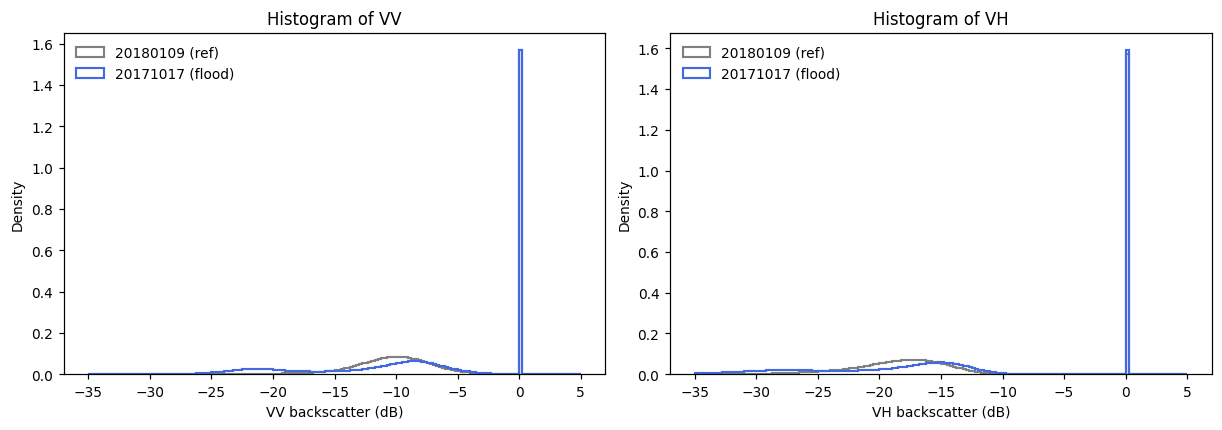

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for ax, pol in zip(axes, ['VV', 'VH']):
    bins = np.linspace(-35, 5, 161)
    for key, color in [('ref', 'gray'), ('flood', 'royalblue')]:
        a = img[key, pol]
        ax.hist(a[np.isfinite(a)], bins=bins, density=True, histtype='step', color=color,
                linewidth=1.4, label=f'{dates[key]} ({key})')
    ax.set_xlabel(f'{pol} backscatter (dB)'); ax.set_ylabel('Density'); ax.legend(frameon=False)
    ax.set_title(f'Histogram of {pol}')
plt.show()

## 5. Backscatter ตามสิ่งปกคลุมดิน
ใช้ ESA WorldCover แบ่งกลุ่มจุดภาพ แล้วหาค่าเฉลี่ย VH ของแต่ละกลุ่มในสองวัน คลาสที่ค่าเฉลี่ย **ลดลงมาก** ในวันน้ำท่วมคือคลาสที่ถูกน้ำท่วมเป็นบริเวณกว้าง

ค่าเฉลี่ยคำนวณบน linear power แล้วแปลงกลับเป็น dB

In [6]:
wc = su.read_on_grid(f'{DATA}/worldcover_2020.tif', grid, 'nearest')
valid = np.isfinite(img['ref', 'VH']) & np.isfinite(img['flood', 'VH']) & np.isfinite(wc)

rows = []
for code, (name, _) in su.WORLDCOVER.items():
    m = valid & (wc == code)
    if m.sum() / valid.sum() < 0.002:        # ข้ามคลาสที่มีพื้นที่น้อยกว่า 0.2%
        continue
    mean_db = {k: su.lin2db(su.db2lin(img[k, 'VH'][m]).mean()) for k in ['ref', 'flood']}
    rows.append({'class': name, 'area_%': 100 * m.sum() / valid.sum(),
                 'VH_ref_dB': mean_db['ref'], 'VH_flood_dB': mean_db['flood'],
                 'change_dB': mean_db['flood'] - mean_db['ref']})
lulc_stats = pd.DataFrame(rows).round(2)
lulc_stats

,class,area_%,VH_ref_dB,VH_flood_dB,change_dB
0,Tree cover,4.68,-14.43,-13.65,0.78
1,Grassland,0.28,-16.80,-15.55,1.25
2,Cropland,52.05,-17.49,-17.21,0.27
3,Built-up,1.31,-14.54,-13.58,0.96
4,Bare / sparse,1.99,-16.51,-15.49,1.02
5,Permanent water,0.38,-22.61,-22.41,0.19


## 6. ภาพผสมสี (RGB composite)

**แบบที่ 1 ผสม polarization ของวันเดียว** R = VV, G = VH, B = VV − VH (ผลต่างใน dB เท่ากับอัตราส่วน VV/VH ในหน่วย linear)
ใช้แยกประเภทพื้นผิว เช่น ผิวน้ำออกดำหรือน้ำเงินเข้ม พืชหนาแน่นออกเขียว สิ่งปลูกสร้างออกสว่างโทนเหลืองหรือชมพู

**แบบที่ 2 ผสมสองช่วงเวลา** R = VH ภาพอ้างอิง, G = B = VH ภาพน้ำท่วม
- พื้นที่ไม่เปลี่ยนแปลง สามช่องเท่ากัน จึงเป็น **สีเทา**
- พื้นที่น้ำท่วม ภาพอ้างอิงสว่างแต่ภาพน้ำท่วมมืด จึงเป็น **สีแดง**
- น้ำถาวร มืดทั้งสองวัน จึงเป็น **สีดำ**
- พื้นที่ที่สว่างขึ้นในวันน้ำท่วม เป็น **สีฟ้า (cyan)**

บันทึก: outputs/fig01_rgb_composites.png


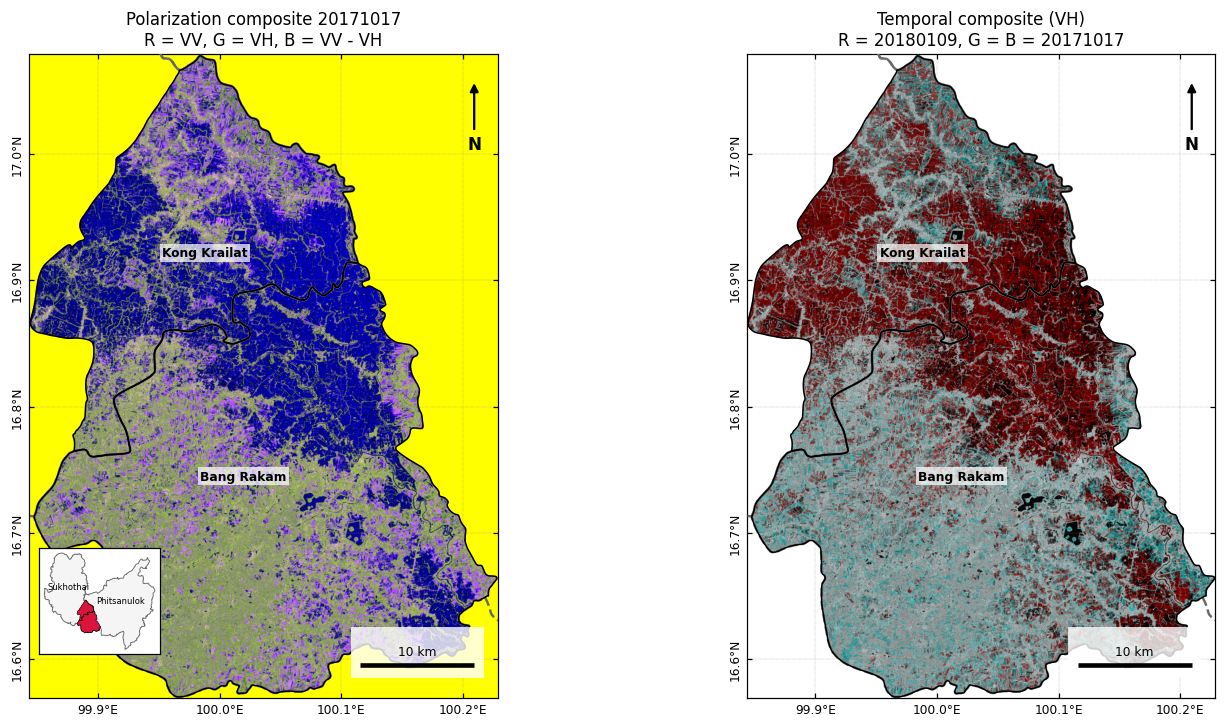

In [7]:
vv, vh = img['flood', 'VV'], img['flood', 'VH']
rgb_pol = np.dstack([su.stretch(vv, -20, 0), su.stretch(vh, -27, -7), su.stretch(vv - vh, 2, 12)])
rgb_time = np.dstack([su.stretch(img['ref', 'VH'], -27, -7),
                      su.stretch(img['flood', 'VH'], -27, -7),
                      su.stretch(img['flood', 'VH'], -27, -7)])

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), constrained_layout=True)
for ax, rgb, title in zip(axes, [rgb_pol, rgb_time],
                          [f'Polarization composite {su.FLOOD_TAG}\nR = VV, G = VH, B = VV - VH',
                           f'Temporal composite (VH)\nR = {su.REF_TAG}, G = B = {su.FLOOD_TAG}']):
    ax.imshow(rgb, extent=su.extent(grid))
    su.journal_map(ax, grid, amphoe, province)
    ax.set_title(title)
su.add_inset(axes[0], amphoe, province)
su.save_fig(fig, 'fig01_rgb_composites.png')
plt.show()

## 7. แบบฝึกหัด

### ข้อ 1 แปลงหน่วย
จุดภาพหนึ่งมีค่า VH = −15 dB ในภาพอ้างอิง และ −25 dB ในภาพน้ำท่วม พลังงานที่สะท้อนกลับลดลงกี่เท่า ลองเขียนโค้ดตรวจด้วย `su.db2lin`

<details><summary><b>เฉลย</b></summary>

ผลต่าง = −25 − (−15) = −10 dB และ $10^{-10/10} = 0.1$ พลังงานจึงเหลือ 1 ใน 10 หรือลดลง 10 เท่า

```python
print(su.db2lin(-25) / su.db2lin(-15))   # 0.1
```
จำง่าย ๆ: −3 dB คือเหลือครึ่งหนึ่ง และ −10 dB คือเหลือหนึ่งในสิบ
</details>

### ข้อ 2 ค่าเฉลี่ยบน dB กับบน linear
สุ่มค่า VH ของภาพอ้างอิงมา 100,000 จุดภาพ แล้วหาค่าเฉลี่ยสองวิธี คือ (ก) เฉลี่ยค่า dB ตรง ๆ (ข) แปลงเป็น linear เฉลี่ย แล้วแปลงกลับ สองค่าต่างกันเท่าไร เพราะอะไร

<details><summary><b>เฉลย</b></summary>

```python
a = img['ref', 'VH']; v = a[np.isfinite(a)]
v = np.random.default_rng(0).choice(v, 100_000)
print('เฉลี่ยบน dB    :', v.mean())
print('เฉลี่ยบน linear:', su.lin2db(su.db2lin(v).mean()))
```
ค่าเฉลี่ยบน dB จะต่ำกว่าเสมอ เพราะ log เป็นฟังก์ชันเว้าคว่ำ (Jensen's inequality) การเฉลี่ย dB เท่ากับการหาค่าเฉลี่ยเรขาคณิตของพลังงาน ยิ่งภาพมี speckle มาก สองค่ายิ่งต่างกัน จึงต้องกรองภาพบนค่า linear
</details>

### ข้อ 3 อ่านภาพผสมสี
ในภาพผสมสองช่วงเวลา ให้หาบริเวณสีแดง สีดำ และสีฟ้า อย่างละหนึ่งแห่ง แล้วอธิบายว่าน่าจะเป็นพื้นผิวแบบใด เทียบกับตารางในส่วนที่ 5 ว่าคลาสใดมีค่า `change_dB` ติดลบมากที่สุด

<details><summary><b>เฉลย</b></summary>

- **แดง:** น้ำท่วมบนพื้นที่ที่ปกติแห้ง ส่วนใหญ่ควรตรงกับพื้นที่เพาะปลูกในที่ราบลุ่ม
- **ดำ:** แหล่งน้ำถาวร เช่น แม่น้ำ บึง อ่างเก็บน้ำ
- **ฟ้า:** พื้นที่ที่ backscatter สูงขึ้นในเดือนตุลาคม เช่น พืชที่กำลังเติบโต หรือพืชที่มีน้ำท่วมโคนจนเกิด double bounce

คลาสที่ `change_dB` ติดลบมากที่สุดคือคลาสที่ถูกท่วมเป็นสัดส่วนมากที่สุด ให้อ่านจากตารางของข้อมูลจริง
</details>

### ข้อ 4 คิดต่อ
ทำไมบทเรียนถัดไปจึงเลือก VH เป็นหลักในการตรวจจับน้ำท่วม และมีสถานการณ์ใดที่ VV อาจดีกว่า

<details><summary><b>เฉลย</b></summary>

VH บนผิวน้ำเปิดต่ำมากและได้รับผลจากลมที่ทำให้ผิวน้ำเป็นคลื่นน้อยกว่า VV จึงแยกน้ำกับแผ่นดินได้คงที่กว่า ส่วน VV ไวต่อ double bounce จึงมีประโยชน์เมื่อน้ำท่วมอยู่ใต้พืชหรือระหว่างอาคาร ซึ่งทำให้ภาพสว่างขึ้นแทนที่จะมืดลง UN-SPIDER ก็แนะนำ VH เป็นค่าเริ่มต้น และให้ทดลอง VV เปรียบเทียบตามพื้นที่ศึกษา
</details>

## สรุป
- GRD เป็น product ที่พร้อมใช้สำหรับงานแผนที่น้ำท่วม ค่าจุดภาพคือ $\sigma^0$ ในหน่วย dB
- ผิวน้ำนิ่งสะท้อนแบบกระจกเงา จึงมืดทั้ง VV และ VH
- ภาพผสมสองช่วงเวลาทำให้เห็นพื้นที่น้ำท่วมได้ด้วยตา ก่อนจะวัดเป็นตัวเลข

**ถัดไป:** `02` เปลี่ยนสิ่งที่เห็นด้วยตาให้เป็นแผนที่น้ำท่วมด้วย change detection และ threshold